### Empirical *probability mass function* of the First Generated Word


In [1]:
import os
import sys
import pickle

project_path = os.path.normpath(os.path.join(os.getcwd(),'..','..'))
if not project_path in sys.path:
    sys.path.append(project_path)
    
import requests
import json
import re
import math
from collections import Counter
import matplotlib.pyplot as plt

from utils.myems.experiments import Experiment
from llmengines.myclient import myLlamacppClient
from exp_0_src import extract_first_word, compute_entropy, generate_figures


**1. Check status of LLM inference engine (container's status)**

In [ ]:
endpoint_uri = 'http://localhost:8081/health'
response = requests.get(endpoint_uri)

print(response.status_code) # you should see : 200
print(response.json()) # you should see : {'status': 'ok'}

client = myLlamacppClient(base_url='http://localhost:8081/')
client.get_loaded_model()
client.wait_for_healthy(endpoint_uri)
print(client.container_id)
print(client._get_container_id())
print(client.docker_compose_file)
#["docker-compose", "--file", client .docker_compose_file, "ps", "-q", 'service_name']
#print(os.listdir(os.path.join(client.docker_compose_file,'..')))
import subprocess
env = os.environ.copy()
#env.setdefault("MODEL_NAME", "dummy")  # satisfies interpolation, not actually used
command = ["docker-compose", "--file", client.docker_compose_file, "ps", "-q", "llama-server"]
result = subprocess.run(command, capture_output=True, text=True, env=env)

print(result)


200
{'status': 'ok'}
DEBUG container_id: None
DEBUG model_name returned: ''
Container is healthy after 0.01 seconds.
Response: {'status': 'ok'}
None
None
c:/Users/juanf/OneDrive/Documents/GitHub/Local-LLM-Experiments/llmengines/docker-compose.yaml
CompletedProcess(args=['docker-compose', '--file', 'c:/Users/juanf/OneDrive/Documents/GitHub/Local-LLM-Experiments/llmengines/docker-compose.yaml', 'ps', '-q', 'llama-server'], returncode=1, stdout='', stderr='error while interpolating services.llama-server.environment.[]: required variable MODEL_NAME is missing a value: error\n')


In [7]:
prompt = "Pick an animal name at random. Any species. Only output that single word, nothing else."

#data = client.get_next_token_probabilities(prompt, temperature=0)

pmf = client.word_pmf(prompt, temperature=5)

([<matplotlib.axis.XTick at 0x15241584850>,
 [Text(0, 0, 'Elephant'),
  Text(1, 0, 'Kangaroo'),
  Text(2, 0, 'Giraffe'),
  Text(3, 0, 'Lion'),
  Text(4, 0, 'Rhinoceros'),
  Text(5, 0, 'Dolphin'),
  Text(6, 0, 'Lemur'),
  Text(7, 0, 'Hyena'),
  Text(8, 0, 'Jaguar'),
  Text(9, 0, 'Leopard'),
  Text(10, 0, 'Gorilla'),
  Text(11, 0, 'Cheetah'),
  Text(12, 0, 'Hippopotamus'),
  Text(13, 0, 'Aardvark'),
  Text(14, 0, 'Buffalo'),
  Text(15, 0, 'Rhino'),
  Text(16, 0, 'Koala'),
  Text(17, 0, 'Tiger'),
  Text(18, 0, 'Wolf'),
  Text(19, 0, 'Otter'),
  Text(20, 0, 'Porcupine'),
  Text(21, 0, 'Sloth'),
  Text(22, 0, 'Falcon'),
  Text(23, 0, 'Raccoon'),
  Text(24, 0, 'Panthera'),
  Text(25, 0, 'Panther'),
  Text(26, 0, 'Tapir'),
  Text(27, 0, 'Eagle'),
  Text(28, 0, 'Emu'),
  Text(29, 0, 'Eland')])

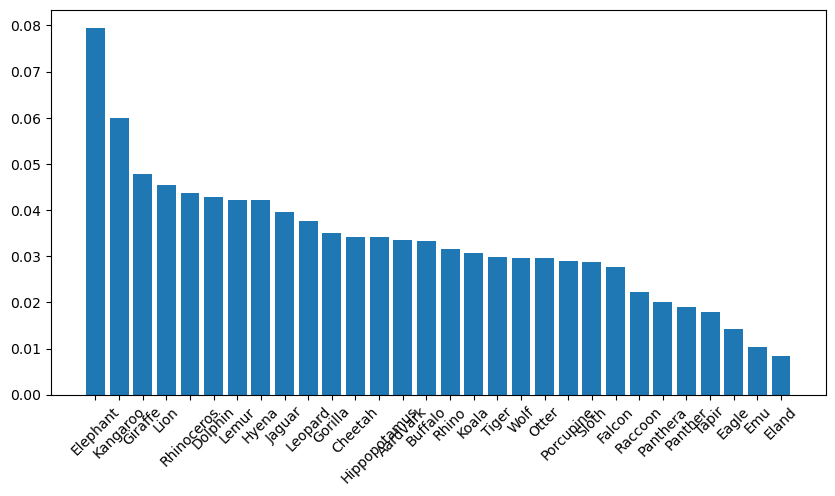

In [8]:
import numpy as np
probs = []
all_words = []
for i, item in enumerate(pmf.most_common()):
    #if i < 40:
    all_words.append(item[0])
    probs.append(item[1])

x = np.arange(len(all_words))

plt.figure(figsize=(10,5))
plt.bar(x,probs)
plt.xticks(x, all_words, rotation=45, fontsize=10)
#all_words

In [9]:
type(pmf)

collections.Counter

([<matplotlib.axis.XTick at 0x152417c6c50>,
 [Text(0, 0, 'Elephant'),
  Text(1, 0, 'Kangaroo'),
  Text(2, 0, 'Giraffe'),
  Text(3, 0, 'Lion'),
  Text(4, 0, 'Rhinoceros'),
  Text(5, 0, 'Dolphin'),
  Text(6, 0, 'Lemur'),
  Text(7, 0, 'Hyena'),
  Text(8, 0, 'Jaguar'),
  Text(9, 0, 'Leopard'),
  Text(10, 0, 'Gorilla'),
  Text(11, 0, 'Cheetah'),
  Text(12, 0, 'Hippopotamus'),
  Text(13, 0, 'Aardvark'),
  Text(14, 0, 'Buffalo'),
  Text(15, 0, 'Rhino'),
  Text(16, 0, 'Koala'),
  Text(17, 0, 'Tiger'),
  Text(18, 0, 'Wolf'),
  Text(19, 0, 'Otter')])

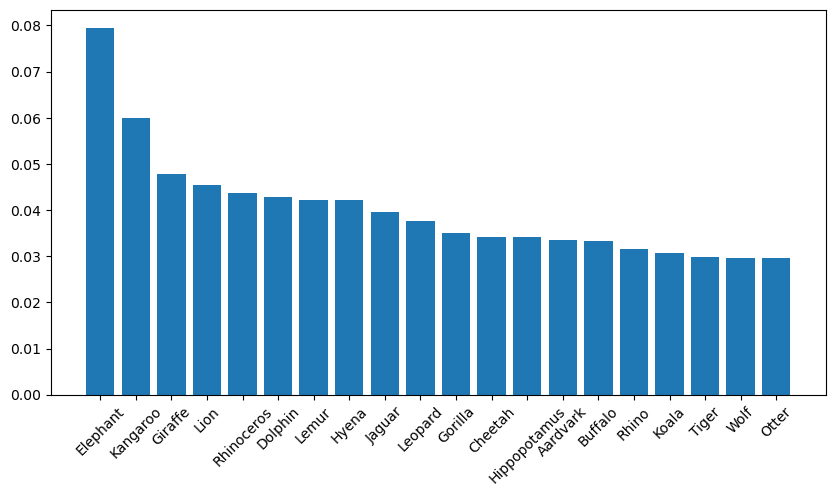

In [10]:
import numpy as np
probs = []
all_words = []
for i, item in enumerate(pmf.most_common()):
    if i < 20:
        all_words.append(item[0])
        probs.append(item[1])

x = np.arange(len(all_words))

plt.figure(figsize=(10,5))
plt.bar(x,probs)
plt.xticks(x, all_words, rotation=45, fontsize=10)
#all_words

In [11]:
for token in data['completion_probabilities']:
    #print(token['id'],token['token'])
    print(len(token['top_logprobs']), token['top_logprobs'])

40 [{'id': 13218, 'token': ' Ele', 'bytes': [32, 69, 108, 101], 'logprob': -1.2411457300186157}, {'id': 11050, 'token': ' Rh', 'bytes': [32, 82, 104], 'logprob': -1.8131587505340576}, {'id': 1292, 'token': ' K', 'bytes': [32, 75], 'logprob': -2.0083844661712646}, {'id': 26328, 'token': ' Gir', 'bytes': [32, 71, 105, 114], 'logprob': -3.1375300884246826}, {'id': 1088, 'token': ' T', 'bytes': [32, 84], 'logprob': -3.199223279953003}, {'id': 1181, 'token': ' E', 'bytes': [32, 69], 'logprob': -3.2487800121307373}, {'id': 24004, 'token': ' Lion', 'bytes': [32, 76, 105, 111, 110], 'logprob': -3.28885817527771}, {'id': 11308, 'token': ' Hy', 'bytes': [32, 72, 121], 'logprob': -3.565911054611206}, {'id': 11324, 'token': ' Lem', 'bytes': [32, 76, 101, 109], 'logprob': -3.614307165145874}, {'id': 15820, 'token': ' Dol', 'bytes': [32, 68, 111, 108], 'logprob': -3.6279990673065186}, {'id': 19440, 'token': ' Jag', 'bytes': [32, 74, 97, 103], 'logprob': -4.055771350860596}, {'id': 27640, 'token': ' Leop', 'bytes': [32, 76, 101, 111, 112], 'logprob': -4.227218151092529}, {'id': 8455, 'token': ' Pan', 'bytes': [32, 80, 97, 110], 'logprob': -4.351495265960693}, {'id': 1167, 'token': ' R', 'bytes': [32, 82], 'logprob': -4.417365550994873}, {'id': 24088, 'token': ' Gor', 'bytes': [32, 71, 111, 114], 'logprob': -4.695718288421631}, {'id': 1098, 'token': ' A', 'bytes': [32, 65], 'logprob': -4.8236517906188965}, {'id': 1150, 'token': ' H', 'bytes': [32, 72], 'logprob': -4.831047534942627}, {'id': 28868, 'token': ' Buffalo', 'bytes': [32, 66, 117, 102, 102, 97, 108, 111], 'logprob': -4.868157863616943}, {'id': 5305, 'token': ' Che', 'bytes': [32, 67, 104, 101], 'logprob': -4.9037957191467285}, {'id': 14788, 'token': ' Ko', 'bytes': [32, 75, 111], 'logprob': -5.14545202255249}, {'id': 12901, 'token': ' Ot', 'bytes': [32, 79, 116], 'logprob': -5.249057292938232}, {'id': 5532, 'token': ' Sl', 'bytes': [32, 83, 108], 'logprob': -5.32147741317749}, {'id': 17995, 'token': ' Wolf', 'bytes': [32, 87, 111, 108, 102], 'logprob': -5.408083438873291}, {'id': 1822, 'token': ' Z', 'bytes': [32, 90], 'logprob': -5.684298038482666}, {'id': 13169, 'token': ' Por', 'bytes': [32, 80, 111, 114], 'logprob': -5.720025539398193}, {'id': 17419, 'token': ' Fal', 'bytes': [32, 70, 97, 108], 'logprob': -5.77186918258667}, {'id': 1219, 'token': ' O', 'bytes': [32, 79], 'logprob': -6.0630011558532715}, {'id': 2111, 'token': ' De', 'bytes': [32, 68, 101], 'logprob': -6.178767681121826}, {'id': 1161, 'token': ' L', 'bytes': [32, 76], 'logprob': -6.2568583488464355}, {'id': 7272, 'token': ' Ok', 'bytes': [32, 79, 107], 'logprob': -6.375880718231201}, {'id': 1135, 'token': ' P', 'bytes': [32, 80], 'logprob': -6.41919469833374}, {'id': 16858, 'token': ' Gib', 'bytes': [32, 71, 105, 98], 'logprob': -6.563560962677002}, {'id': 1152, 'token': ' D', 'bytes': [32, 68], 'logprob': -6.645003795623779}, {'id': 27929, 'token': ' Gaz', 'bytes': [32, 71, 97, 122], 'logprob': -6.6652374267578125}, {'id': 16743, 'token': ' Lyn', 'bytes': [32, 76, 121, 110], 'logprob': -6.7116217613220215}, {'id': 1711, 'token': ' Wh', 'bytes': [32, 87, 104], 'logprob': -6.736450672149658}, {'id': 4589, 'token': ' Ant', 'bytes': [32, 65, 110, 116], 'logprob': -6.9336676597595215}, {'id': 18810, 'token': ' Pel', 'bytes': [32, 80, 101, 108], 'logprob': -7.0026679039001465}, {'id': 1188, 'token': ' G', 'bytes': [32, 71], 'logprob': -7.019397258758545}, {'id': 6255, 'token': ' Cam', 'bytes': [32, 67, 97, 109], 'logprob': -7.055360317230225}]
40 [{'id': 18721, 'token': 'phant', 'bytes': [112, 104, 97, 110, 116], 'logprob': -1.919287933560554e-05}, {'id': 1489, 'token': 'ph', 'bytes': [112, 104], 'logprob': -11.605087280273438}, {'id': 10490, 'token': 'phas', 'bytes': [112, 104, 97, 115], 'logprob': -11.786600112915039}, {'id': 19826, 'token': 'phan', 'bytes': [112, 104, 97, 110], 'logprob': -13.386204719543457}, {'id': 3610, 'token': 'php', 'bytes': [112, 104, 112], 'logprob': -14.335046768188477}, {'id': 25380, 'token': 'PHP', 'bytes': [80, 72, 80], 'logprob': -15.793207168579102}, {'id': 2787, 'token': 'pha', 'bytes': [112, 104, 97], 'logprob': -15.914196968078613}, {'id': 7977, 'token': 'PH', 'bytes': [80, 72], 'logprob': -17.16390037536621}, {'id': 29488, 'token': 'p', 'bytes': [112], 'logprob': -17.43332862854004}, {'id': 4098, 'token': 'Ph', 'bytes': [80, 104], 'logprob': -17.60623550415039}, {'id': 13218, 'token': ' Ele', 'bytes': [32, 69, 108, 101], 'logprob': -17.71731185913086}, {'id': 6707, 'token': ' ele', 'bytes': [32, 101, 108, 101], 'logprob': -17.95157241821289}, {'id': 2740, 'token': ' Ph', 'bytes': [32, 80, 104], 'logprob': -18.520944595336914}, {'id': 29490, 'token': 'f', 'bytes': [102], 'logprob': -18.769351959228516}, {'id': 27079, 'token': 'phabet', 'bytes': [112, 104, 97, 98, 101, 116], 'logprob': -18.79187774658203}, {'id': 7458, 'token': 'phone', 'bytes': [112, 104, 111, 110, 101], 'logprob': -18.97583770751953}, {'id': 23094, 'token': 'phony', 'bytes': [112, 104, 111, 110, 121], 'logprob': -19.101598739624023}, {'id': 3894, 'token': 'oph', 'bytes': [111, 112, 104], 'logprob': -19.292936325073242}, {'id': 1876, 'token': ' ph', 'bytes': [32, 112, 104], 'logprob': -19.331750869750977}, {'id': 28385, 'token': 'phrase', 'bytes': [112, 104, 114, 97, 115, 101], 'logprob': -19.44675636291504}, {'id': 15193, 'token': 'uther', 'bytes': [117, 116, 104, 101, 114], 'logprob': -19.688003540039062}, {'id': 22325, 'token': 'pent', 'bytes': [112, 101, 110, 116], 'logprob': -19.770278930664062}, {'id': 20293, 'token': 'phase', 'bytes': [112, 104, 97, 115, 101], 'logprob': -19.835500717163086}, {'id': 24138, 'token': 'pher', 'bytes': [112, 104, 101, 114], 'logprob': -19.865367889404297}, {'id': 1839, 'token': 'vent', 'bytes': [118, 101, 110, 116], 'logprob': -19.98467254638672}, {'id': 12265, 'token': 'pb', 'bytes': [112, 98], 'logprob': -20.42207145690918}, {'id': 2411, 'token': 'ele', 'bytes': [101, 108, 101], 'logprob': -20.447032928466797}, {'id': 3134, 'token': 'aph', 'bytes': [97, 112, 104], 'logprob': -20.538997650146484}, {'id': 27908, 'token': 'eph', 'bytes': [101, 112, 104], 'logprob': -20.620342254638672}, {'id': 6288, 'token': 'pret', 'bytes': [112, 114, 101, 116], 'logprob': -20.66776466369629}, {'id': 3931, 'token': 'phi', 'bytes': [112, 104, 105], 'logprob': -20.682762145996094}, {'id': 11250, 'token': 'asant', 'bytes': [97, 115, 97, 110, 116], 'logprob': -20.939952850341797}, {'id': 29614, 'token': 'ф', 'bytes': [209, 132], 'logprob': -20.94098663330078}, {'id': 20962, 'token': ' PHP', 'bytes': [32, 80, 72, 80], 'logprob': -20.967334747314453}, {'id': 12037, 'token': 'plus', 'bytes': [112, 108, 117, 115], 'logprob': -21.006235122680664}, {'id': 8839, 'token': 'phy', 'bytes': [112, 104, 121], 'logprob': -21.02927017211914}, {'id': 2157, 'token': 'par', 'bytes': [112, 97, 114], 'logprob': -21.112627029418945}, {'id': 9568, 'token': 'phere', 'bytes': [112, 104, 101, 114, 101], 'logprob': -21.226879119873047}, {'id': 29482, 'token': 'l', 'bytes': [108], 'logprob': -21.273719787597656}, {'id': 28471, 'token': ' Phillips', 'bytes': [32, 80, 104, 105, 108, 108, 105, 112, 115], 'logprob': -21.32321548461914}]
40 [{'id': 2, 'token': '', 'bytes': [], 'logprob': -0.00026664711185730994}, {'id': 781, 'token': '\n', 'bytes': [10], 'logprob': -8.240882873535156}, {'id': 29491, 'token': '.', 'bytes': [46], 'logprob': -13.072521209716797}, {'id': 1093, 'token': ' (', 'bytes': [32, 40], 'logprob': -14.818652153015137}, {'id': 1241, 'token': 'ine', 'bytes': [105, 110, 101], 'logprob': -15.069622039794922}, {'id': 29524, 'token': '\\', 'bytes': [92], 'logprob': -16.3377685546875}, {'id': 1182, 'token': ' \\', 'bytes': [32, 92], 'logprob': -16.343570709228516}, {'id': 29576, 'token': '!', 'bytes': [33], 'logprob': -17.008941650390625}, {'id': 29493, 'token': ',', 'bytes': [44], 'logprob': -17.070436477661133}, {'id': 29703, 'token': '\u200b', 'bytes': [226, 128, 139], 'logprob': -17.180419921875}, {'id': 29473, 'token': ' ', 'bytes': [32], 'logprob': -17.671894073486328}, {'id': 4334, 'token': ' (\\', 'bytes': [32, 40, 92], 'logprob': -18.62407875061035}, {'id': 14816, 'token': '\\_', 'bytes': [92, 95], 'logprob': -18.906139373779297}, {'id': 1315, 'token': 'ide', 'bytes': [105, 100, 101], 'logprob': -18.97863006591797}, {'id': 29572, 'token': '?', 'bytes': [63], 'logprob': -19.14876937866211}, {'id': 29510, 'token': "'", 'bytes': [39], 'logprob': -19.166976928710938}, {'id': 1869, 'token': '...', 'bytes': [46, 46, 46], 'logprob': -19.215173721313477}, {'id': 1574, 'token': 'oid', 'bytes': [111, 105, 100], 'logprob': -19.470630645751953}, {'id': 1256, 'token': 'ard', 'bytes': [97, 114, 100], 'logprob': -19.566177368164062}, {'id': 1338, 'token': 'ite', 'bytes': [105, 116, 101], 'logprob': -19.624210357666016}, {'id': 19591, 'token': ' \\(', 'bytes': [32, 92, 40], 'logprob': -19.6350154876709}, {'id': 29501, 'token': '-', 'bytes': [45], 'logprob': -19.904254913330078}, {'id': 29516, 'token': '/', 'bytes': [47], 'logprob': -19.941810607910156}, {'id': 8073, 'token': 'idae', 'bytes': [105, 100, 97, 101], 'logprob': -20.04463005065918}, {'id': 2139, 'token': 'oh', 'bytes': [111, 104], 'logprob': -20.045631408691406}, {'id': 1064, 'token': 'ion', 'bytes': [105, 111, 110], 'logprob': -20.079166412353516}, {'id': 29499, 'token': ')', 'bytes': [41], 'logprob': -20.121227264404297}, {'id': 1501, 'token': ' [', 'bytes': [32, 91], 'logprob': -20.14016342163086}, {'id': 3755, 'token': ' \\\\', 'bytes': [32, 92, 92], 'logprob': -20.23653793334961}, {'id': 29515, 'token': ':', 'bytes': [58], 'logprob': -20.25773811340332}, {'id': 1208, 'token': 'ant', 'bytes': [97, 110, 116], 'logprob': -20.265480041503906}, {'id': 15876, 'token': ' :)', 'bytes': [32, 58, 41], 'logprob': -20.277952194213867}, {'id': 29504, 'token': '*', 'bytes': [42], 'logprob': -20.297916412353516}, {'id': 16526, 'token': ' \u200b', 'bytes': [32, 226, 128, 139], 'logprob': -20.422428131103516}, {'id': 1116, 'token': '**', 'bytes': [42, 42], 'logprob': -20.479877471923828}, {'id': 29476, 'token': 'a', 'bytes': [97], 'logprob': -20.48779296875}, {'id': 1303, 'token': 'ice', 'bytes': [105, 99, 101], 'logprob': -20.526870727539062}, {'id': 1072, 'token': ' and', 'bytes': [32, 97, 110, 100], 'logprob': -20.537633895874023}, {'id': 29513, 'token': ';', 'bytes': [59], 'logprob': -20.538253784179688}, {'id': 1190, 'token': ' #', 'bytes': [32, 35], 'logprob': -20.583284378051758}]

<>:5: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?
<>:6: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?
<>:7: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?
<>:5: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?
<>:6: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?
<>:7: SyntaxWarning: 'int' object is not subscriptable; perhaps you missed a comma?


NameError: name 'data' is not defined

**2. Define function to sample LLM responses provided a parameter configuration**

In [2]:
# -----------------------------
# Sampling function : sample responses
# from probability that first word is an animal given the prompt
# -----------------------------

def run_experiment(parameters : dict, N=1000):
    """ Collects text responses to a fixed prompt over N independent chats.
        We sample each text response at the first word, which can be considered
        a discrete random variable over the space of words/tokens.
        for each unique word, we count repetitions over the N independent chats,
        which gives us up to a normalizing constant an empirical prob. mass function
        of the first word.
    """
    
    counter = Counter()
    llm_responses = {}
    for i in range(N):

        payload = {
            #"model": parameters['model_name'],
            "messages": [
                {"role": "user", 
                 "content": parameters['prompt']}
            ],
            "temperature": parameters['temperature'],
            "max_tokens": parameters['max_tokens'],
            "stream": parameters['stream'],            
            #"top_k": 50,
            #"top_p": 1.0,
        }

        headers = {"Content-Type": "application/json"}
        endpoint_url = parameters.get('endpoint_url')

        response = requests.post(endpoint_url, headers=headers, json=payload)
        data = response.json()

        try:
            text = data["choices"][0]["message"]["content"]
            llm_responses[i] = text
        except:
            continue

        first_word = extract_first_word(text)

        if first_word:
            counter[first_word] += 1

    return counter, llm_responses

c57d7dd0
{'endpoint_url': 'http://localhost:8081/v1/chat/completions', 'model_name': 'Mistral-7B-Instruct-v0.3-Q4_K_M.gguf', 'prompt': 'Pick an animal name at random. Any species. Only output that single word, nothing else.', 'n_samples': 50, 'temperature': 0.2, 'max_tokens': 10, 'stream': False}
Loading model Mistral-7B-Instruct-v0.3-Q4_K_M.gguf into llama.cpp server
Expected models directory : c:\Users\juanf\OneDrive\Documents\GitHub\Local-LLM-Experiments\models
Container is healthy after 0.03 seconds.
Response: {'status': 'ok'}
DEBUG container_id: None
DEBUG model_name returned: ''
Stopping current container...
Stopped: 
Starting container with model: Mistral-7B-Instruct-v0.3-Q4_K_M.gguf
Started: 
Container is healthy after 0.01 seconds.
Response: {'status': 'ok'}
Ready! Model Mistral-7B-Instruct-v0.3-Q4_K_M.gguf is live.
Running temperature 0.2...
Unique animals: 3
Entropy: 0.5949445538525273
9f38a8fd
{'endpoint_url': 'http://localhost:8081/v1/chat/completions', 'model_name': 'Mist

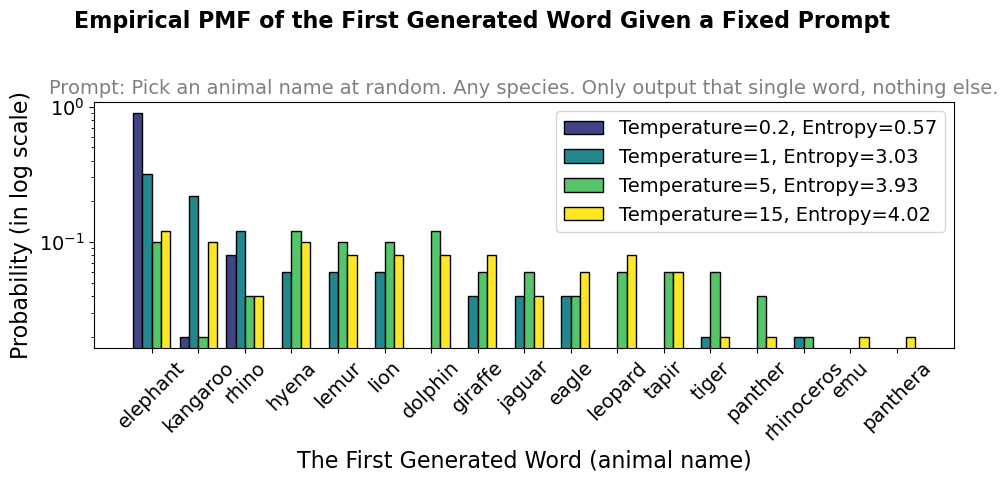

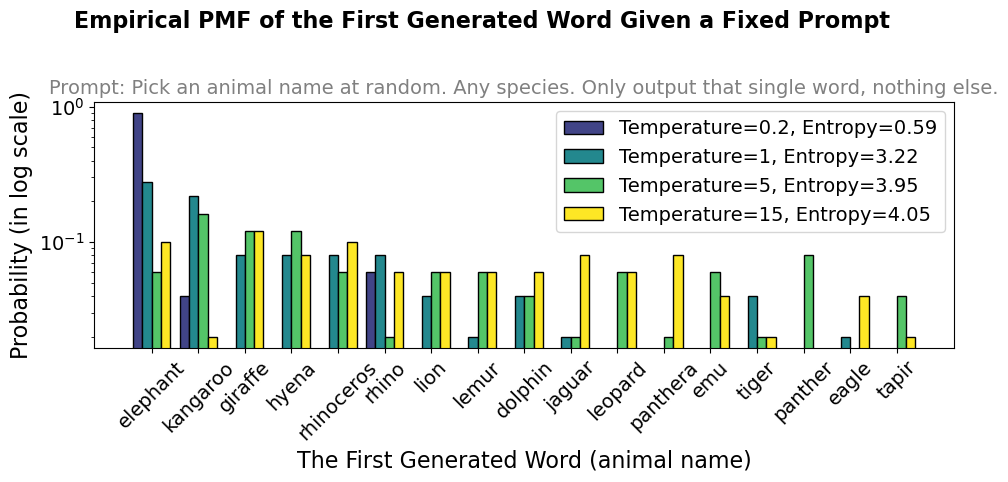

Meta-Llama-3.1-8B-Instruct-Q4_K_M.gguf
Mistral-7B-Instruct-v0.3-Q4_K_M.gguf


In [5]:
experiments_dir = os.path.join(project_path,"experiments")

ENDPOINT = "http://localhost:8081/v1/chat/completions"
MODEL_NAME = "Mistral-7B-Instruct-v0.3-Q4_K_M.gguf"
#MODEL_NAME = "Meta-Llama-3.1-8B-Instruct-Q4_K_M.gguf" 
#MODEL_NAME = "mistral-7b-instruct-v0.2.Q4_K_M.gguf"
prompt = "Pick an animal name at random. Respond with a single word."
prompt = "Pick an animal from anywhere at random. Respond with a single word."
prompt = "Name any animal. Respond with a single word." # really bad
prompt = "Pick an animal name at random. Any species. Respond with a single word."
prompt = "Pick an animal name at random. Any species. Only output that single word, nothing else."

# -----------------------------
# CONFIG
# -----------------------------

BASE_URL = "http://localhost:8081/"
ENDPOINT = "http://localhost:8081/v1/chat/completions"
config_template = {
    "endpoint_url" : ENDPOINT,
    "model_name" : MODEL_NAME,    
    #"model_name" : "Meta-Llama-3.1-8B-Instruct-Q4_K_M.gguf"
    "prompt" : prompt,
    "n_samples" : 50,
    "temperature": 0,
    "max_tokens": 10,
    "stream": False
    #"top_k": 50,
    #"top_p": 1.0,
}
# Initialize experiment folder structure

results = {}
entropies = []

# Define hyperparameter grid
models = ["Mistral-7B-Instruct-v0.3-Q4_K_M.gguf","Meta-Llama-3.1-8B-Instruct-Q4_K_M.gguf" ]
temperatures = [0.2,1,5,15]


#client = myLlamacppClient(BASE_URL)
experiment_name = "exp_0"
with Experiment(name=experiment_name,
                params_baseline=config_template,
                base_dir=experiments_dir,
                params_to_study={'model_name': models, 
                                 'temperature' : temperatures}) as exp: 

    
    for config_hash, config in exp.parameter_grid:

        model_name = config.get('model_name')
        temperature = config.get('temperature')
        print(config_hash)
        data = []
        # Get output files related to config_hash
        files = [file for file in os.listdir(exp.outputs_dir) if config_hash in file and file.endswith('.pkl')]                
        if len(files)==1: # files empty skip this conditional
            file = files[0]
            
            print(f'Results already exists in {file}. Loading existing results ...')
            with open(os.path.join(exp.outputs_dir,file), 'rb') as f:
                data = pickle.load(f)
            results[f"{model_name}_{config_hash}"] = data[f"{model_name}_{config_hash}"]
            print(f'Skipping experiment run for config with hash {config_hash}.')
            continue         

        print(config)


        # Load model to llama.cpp server running on a container. 
        # The client verifies whether the model is already loaded beforing attempting to switch it.
        print(f'Loading model {model_name} into llama.cpp server')
        client.switch_model(model_name, health_endpoint="health")

        print(f"Running temperature {temperature}...")
        counter, llm_responses = run_experiment(config, N=config["n_samples"])

        # Save LLM responses 
        exp.save_output(data=llm_responses, 
                        name=f"llm_responses_T_{temperature}_{config_hash}",
                        format='json')
        # Calculate entropy of the PMF (histogram) of first word animals 
        entropy = compute_entropy(counter)

        print("Unique animals:", len(counter))
        print("Entropy:", entropy)

        # Store results for figures
        results[f"{model_name}_{config_hash}"] = {"temperature" : temperature, 
                                "counter" : counter, 
                                "entropy" : entropy,
                                "n_samples" : config["n_samples"]}
        exp.save_output(results,name=f"results_{model_name}_{config_hash}.tmp",format="pkl")
        
    
    
    for model_name, figure_tuple in generate_figures(prompt, results).items():
        print(model_name)
        name, fig = figure_tuple
        exp.save_figure(fig, name, format='svg')

    


In [24]:
import numpy as np
import numpy.linalg as nplin

#A1 = np.array([[0,1,0],[1,0,0],[0,0,0]])
#print(A1)
A1 = np.array([[0,1,0],[1,0,1],[0,1,0]])
A2 = np.array([[0,1,1],[1,0,1],[1,1,0]])
print(A2)

L1 = np.diag(np.sum(A2,1)) - A2

I = np.eye(3,3)

alpha = 0.5

w = np.random.randn(3,1)

print(w)
print(nplin.inv(I + alpha*L1))
print(nplin.inv(I + alpha*L1)@w)

[[0 1 1]
 [1 0 1]
 [1 1 0]]
[[-0.67679904]
 [ 0.33436044]
 [ 0.87193602]]
[[0.6 0.2 0.2]
 [0.2 0.6 0.2]
 [0.2 0.2 0.6]]
[[-0.16482013]
 [ 0.23964366]
 [ 0.45467389]]
